## Initial Code

Our new SkillMap uses the same model and tools as our SkillMap agent. Only who decides the steps changes.

### Set Up VS Code

1. Open this notebook, click **Select Kernel** (top right), and pick a Python 3.10+ environment.

```
GOOGLE_API_KEY=your-gemini-key
TAVILY_API_KEY=your-tavily-key
RAPIDAPI_KEY=your-rapidapi-key
```

### Install the Packages

After the install finishes, click **Restart** in the notebook toolbar once. Then continue from the next cell.

In [ ]:
%pip install -U python-dotenv langchain langchain-google-genai langchain-tavily requests

In [ ]:
import os

import requests
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langchain.tools import tool
from langchain_tavily import TavilySearch
from google.colab import userdata

load_dotenv()

model = init_chat_model("google_genai:gemini-3.5-flash-lite", api_key=userdata.get("GOOGLE_API_KEY"))

skill_demand_tool = TavilySearch(
    max_results=5,
    search_depth="advanced",
    tavily_api_key=userdata.get("TAVILY_API_KEY"),
)


@tool
def search_jobs(skill: str, location: str) -> list:
    """Search for jobs requiring a specific skill using JSearch API from RapidAPI."""
    url = "https://jsearch.p.rapidapi.com/search"

    # Retrieve and safely strip any potential newlines/returns from the API key
    rapidapi_key = userdata.get("RAPIDAPI_KEY")
    if rapidapi_key:
        rapidapi_key = rapidapi_key.strip()

    headers = {
        "x-rapidapi-key": rapidapi_key,
        "x-rapidapi-host": "jsearch.p.rapidapi.com",
    }
    querystring = {
        "query": f"{skill} in {location}",
        "page": "1",
        "country": "in",
        "employment_types": "INTERN,FULLTIME",
        "job_requirements": "no_experience,under_3_years_experience",
    }
    response = requests.get(url, headers=headers, params=querystring)
    data = response.json()
    jobs = data.get("data", [])
    print(f"Found {len(jobs)} jobs\n")

    result = []
    for job in jobs:
      result.append({
      "title": job.get("job_title"),
      "company": job.get("employer_name"),
      "location": job.get("job_city"),
      "apply_link": job.get("job_apply_link")
    })

    return result

In [ ]:
from langchain.agents import create_agent

system_prompt = """You are a Skill-to-Career Mapping assistant that helps students understand skill demand and find matching job opportunities.

You have access to these tools:
- skill_demand_tool: Search for industry demand, salary insights, and career trends
- search_jobs: Find actual job listings requiring specific skills

Help the student by researching the skill they ask about and finding relevant opportunities.

Present results in a clean, readable format with clear sections and proper spacing. Include all job details with apply links. Don't use markdown format."""

agent = create_agent(
    model=model,
    tools=[skill_demand_tool, search_jobs],
    system_prompt=system_prompt,
)

In [ ]:
user_query = "What's the demand for generative ai in the industry and show me related job openings in India"

# response = agent.invoke({
#   "messages": [{"role": "user", "content": user_query}]
# })
# print(response["messages"][-1].content)

for run in range(1, 4):
    response = agent.invoke({"messages": [{"role": "user", "content": user_query}]})
    print(f"\nRun {run}:")
    for message in response["messages"]:
        if message.type == "ai":
            print("  LLM call ->", [call["name"] for call in message.tool_calls] or "final response")

Found 0 jobs


Run 1:
  LLM call -> ['tavily_search']
  LLM call -> ['search_jobs']
  LLM call -> ['tavily_search']
  LLM call -> final response
Found 0 jobs

Found 0 jobs


Run 2:
  LLM call -> ['tavily_search']
  LLM call -> ['search_jobs']
  LLM call -> ['search_jobs']
  LLM call -> final response
Found 0 jobs

Found 0 jobs


Run 3:
  LLM call -> ['tavily_search']
  LLM call -> ['search_jobs']
  LLM call -> ['search_jobs']
  LLM call -> final response


## install Langgraph

In [ ]:
%pip install -U langgraph

  Attempting uninstall: langgraph-prebuilt
    Found existing installation: langgraph-prebuilt 1.1.1
    Uninstalling langgraph-prebuilt-1.1.1:
      Successfully uninstalled langgraph-prebuilt-1.1.1
  Attempting uninstall: langgraph
    Found existing installation: langgraph 1.2.19
    Uninstalling langgraph-1.2.19:
      Successfully uninstalled langgraph-1.2.19
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [langgraph]


## Define State

In [ ]:
from typing_extensions import TypedDict


class State(TypedDict):
    skill: str      # the skill the student asks about, like "Generative AI"
    demand: str     # the industry demand for the skill

### Create the Stategraph

LangGraph gives us `StateGraph`: a **builder** for our graph. We tell it which state the steps share.

**Official docs:** <a href="https://docs.langchain.com/oss/python/langgraph/graph-api#stategraph" target="_blank">StateGraph</a>

In [ ]:
from langgraph.graph import StateGraph

builder = StateGraph(State)

### 3. Add the First Node: find_demand

**Official docs:** <a href="https://docs.langchain.com/oss/python/langgraph/graph-api#nodes" target="_blank">Nodes</a>

In [ ]:
def find_demand(state: State):
    """Tavily + LLM: find the industry demand for the skill"""
    skill = state["skill"]

    query = f"industry demand for {skill} skills in India"
    research = skill_demand_tool.invoke({"query": query})

    prompt = (f"Research: {research} In 3 short lines, "
              f"summarize the industry demand for {skill}.")
    msg = model.invoke(prompt)

    return {"demand": msg.text}

In [ ]:
builder.add_node("find_demand", find_demand)

### Add Edges

In [ ]:
from langgraph.graph import START, END

builder.add_edge(START, "find_demand")
builder.add_edge("find_demand", END)

### Run

In [ ]:
skillmap = builder.compile()

state = skillmap.invoke({"skill": "Generative AI"})
print(state["demand"])

The industry demand for Generative AI in India is surging, driven by startups, GCCs, and tech firms looking to build custom enterprise solutions and automate workflows. 

While demand for specialized roles like Generative AI Engineers, LLM architects, and MLOps professionals is skyrocketing—commanding massive salary premiums—the technology is simultaneously reducing entry-level white-collar hiring. 

Ultimately, the market places the highest value on practical production skills, system deployment, and agentic frameworks over basic coding credentials.


### Visualize the Graph

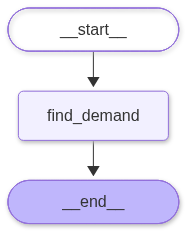

In [ ]:
from IPython.display import Image, display

display(Image(skillmap.get_graph().draw_mermaid_png()))

### Add the Second Step: get_jobs

In [ ]:
class State(TypedDict):
    skill: str      # the skill the student asks about, like "Generative AI"
    demand: str     # the industry demand for the skill
    jobs: dict      # each skill, and its job openings

In [ ]:
def get_jobs(state: State):
    """JSearch: find the job openings for the skill"""
    skill = state["skill"]

    jobs = search_jobs.invoke({"skill": skill, "location": "India"})

    return {"jobs": {skill: jobs}}

In [ ]:
builder = StateGraph(State)
builder.add_node("find_demand", find_demand)
builder.add_node("get_jobs", get_jobs)
builder.add_edge(START, "find_demand")
builder.add_edge("find_demand", "get_jobs")
builder.add_edge("get_jobs", END)
skillmap = builder.compile()

### Add the Third Step: generate_response

In [ ]:
class State(TypedDict):
    skill: str      # the skill the student asks about, like "Generative AI"
    demand: str     # the industry demand for the skill
    jobs: dict      # each skill, and its job openings
    response: str     # the final response for the student

In [ ]:
def generate_response(state: State):
    """LLM: write the final response for the student"""
    skill = state["skill"]
    demand = state["demand"]
    jobs = state["jobs"]

    prompt = (
        f"Write a short answer for a student about {skill}. "
        f"Demand: {demand} "
        f"Jobs for each skill, with apply links: {jobs} "
        "If there is more than one skill, say the extra one is a related skill with more openings. Don't use markdown."
    )
    msg = model.invoke(prompt)

    return {"response": msg.text}

In [ ]:
# Build the graph
builder = StateGraph(State)

# Add nodes
builder.add_node("find_demand", find_demand)
builder.add_node("get_jobs", get_jobs)
builder.add_node("generate_response", generate_response)

# Add edges to connect nodes
builder.add_edge(START, "find_demand")
builder.add_edge("find_demand", "get_jobs")
builder.add_edge("get_jobs", "generate_response")
builder.add_edge("generate_response", END)

# Compile
skillmap = builder.compile()

In [ ]:
state = skillmap.invoke({"skill": "Generative AI"})

print(len(state["jobs"]["Generative AI"]), "job openings")
print(state["response"])

Found 0 jobs

0 job openings
Generative AI is transforming the tech world, with India seeing a massive surge in market demand as enterprises adopt custom solutions, driving a 200 percent jump in course interest and creating millions of tech jobs. The focus has shifted from building foundational models to high-value specializations like production-ready engineering, RAG pipelines, AI agents, MLOps, and vector databases, which command salary premiums of 30 to 50 percent. While senior architects and skilled GenAI engineers earn top tiers of over one crore rupees per annum, automation is tightening entry-level white-collar hiring, making continuous upskilling essential. Jobs for each skill, with apply links: Generative AI: [].


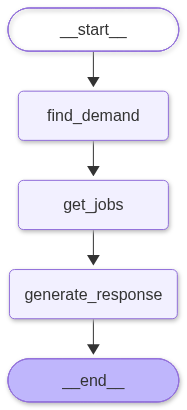

In [ ]:
display(
    Image(
        skillmap.get_graph().draw_mermaid_png()
    )
)

# Step 2: Add a Conditional Edge

In [ ]:
MIN_JOBS = 5


def check_job_count(state: State):
    """Routing function: does the skill have enough job openings?"""
    skill = state["skill"]
    count = len(state["jobs"][skill])

    if count < MIN_JOBS:
        return "Fail"
    return "Pass"

### test

In [ ]:
print(check_job_count({"skill": "SQL", "jobs": {"SQL": [1, 2, 3]}}))
print(check_job_count({"skill": "SQL", "jobs": {"SQL": [1, 2, 3, 4, 5]}}))

Fail
Pass


### Add the Step for "Fail"

In [ ]:
def find_related_skill(state: State):
    """LLM + JSearch: find a related skill with more openings, and its jobs"""
    skill = state["skill"]

    prompt = (f"Suggest one skill related to {skill} that has "
              "more fresher jobs in India. "
              "Reply with only the skill name.")
    msg = model.invoke(prompt)
    related_skill = msg.text.strip()

    related_jobs = search_jobs.invoke({"skill": related_skill,
                                       "location": "India"})

    jobs = dict(state["jobs"])
    jobs[related_skill] = related_jobs

    return {"jobs": jobs}

### connect to Graph

In [ ]:
# Build the graph
builder = StateGraph(State)

# Add nodes
builder.add_node("find_demand", find_demand)
builder.add_node("get_jobs", get_jobs)
builder.add_node("find_related_skill", find_related_skill)
builder.add_node("generate_response", generate_response)

# Add edges to connect nodes
builder.add_edge(START, "find_demand")
builder.add_edge("find_demand", "get_jobs")
builder.add_conditional_edges(
    "get_jobs", check_job_count, {"Pass": "generate_response", "Fail": "find_related_skill"}
)
builder.add_edge("find_related_skill", "generate_response")
builder.add_edge("generate_response", END)

# Compile
skillmap = builder.compile()

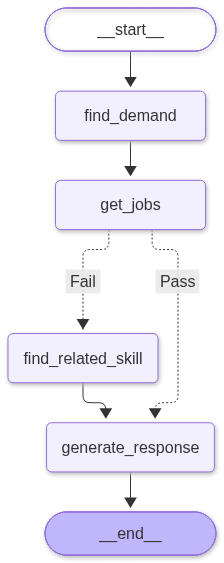

In [ ]:
display(
    Image(
        skillmap.get_graph().draw_mermaid_png()
    )
)